[*********************100%***********************]  1 of 1 completed


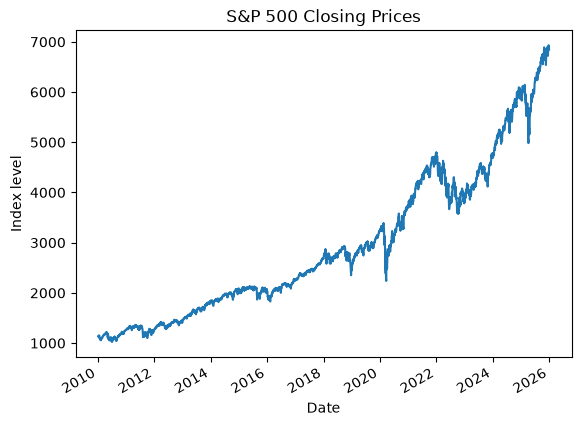

In [1]:
import yfinance as yf
import matplotlib.pyplot as plt
data = yf.download("^GSPC", start="2010-01-01", end="2026-01-01")
prices = data["Close"].squeeze()
prices.plot(title="S&P 500 Closing Prices")
plt.ylabel("Index level")
plt.show()



In [2]:
returns = prices.pct_change().dropna()
print(returns.head())
print("Number of returns:", len(returns))

Date
2010-01-05    0.003116
2010-01-06    0.000546
2010-01-07    0.004001
2010-01-08    0.002882
2010-01-11    0.001747
Name: ^GSPC, dtype: float64
Number of returns: 4023


In [3]:
mean = returns.mean()
std = returns.std()
var_99 = 2.326 * std - mean
print("Mean:", mean)
print("Standard Deviation:", std)
print("99% VaR:", var_99)


Mean: 0.0005069667735064549
Standard Deviation: 0.010916460326292989
99% VaR: 0.024884719945451036


In [4]:
breaches = returns[returns < -var_99]
breach_count = len(breaches)
breach_rate = breach_count / len(returns)
print("Expected breaches:", 0.01 * len(returns))
print("Actual breaches:", breach_count)
print("Breach rate:", breach_rate * 100, "%")

Expected breaches: 40.230000000000004
Actual breaches: 81
Breach rate: 2.013422818791946 %


In [5]:
import numpy as np
from scipy.stats import norm

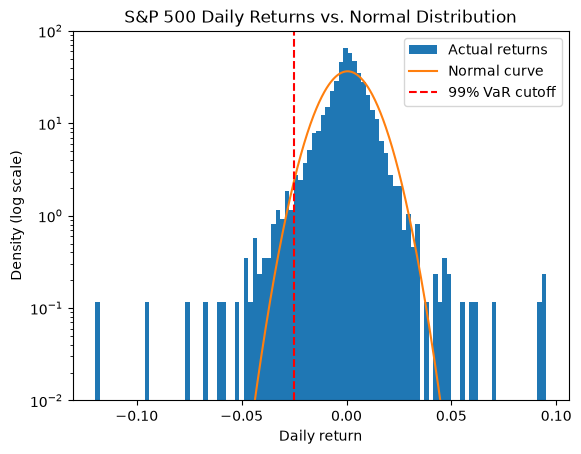

In [6]:
plt.hist(returns, bins=100, density=True, label="Actual returns")

x = np.linspace(returns.min(), returns.max(), 1000)
plt.plot(x, norm.pdf(x, mean, std), label="Normal curve")

plt.axvline(-var_99, color="red", linestyle="--", label="99% VaR cutoff")

plt.yscale("log")
plt.ylim(0.01, 100)
plt.title("S&P 500 Daily Returns vs. Normal Distribution")
plt.xlabel("Daily return")
plt.ylabel("Density (log scale)")
plt.legend()
plt.show()